# Phase 2b: Per-tensor sensitivity + optimizer-based bit allocation

Phase 2 (first version) showed that sensitivity ranking beats *random* block choices but that mixing only Q8_0 and Q2_K could not beat the uniform K-quant presets. This notebook fixes the weak points:

| Improvement | What changes |
|---|---|
| Realistic levels | allowed types per tensor: **q3_k, q4_k, q5_k, q6_k, q8_0** (not just the two extremes) |
| Finer groups | every weight matrix is its own group (**28 blocks x 7 kinds + embeddings, about 197 groups**) |
| Importance matrix | all low-bit candidates **and** the uniform baselines are quantized with an imatrix, so the comparison is fair |
| Optimizer | measured damage per group -> **multiple-choice knapsack (MILP)** picks the level of every group for a size budget, instead of a simple ranking |
| Honest evaluation | imatrix text, damage-measurement text and final test text are **three different slices** of WikiText-2 (train, train, test) |
| Speed | final candidates and presets are also timed with `llama-bench` (GPU tokens/s) |

**Damage model.** Each group is probed on its own: group at q3_k, everything else q8_0, damage = ln(ppl / ppl_ref) on the damage text. A subset of groups is also probed at q4_k/q5_k/q6_k to fit how damage shrinks with more bits. Damages of different groups are assumed to add up. That is an approximation, which is exactly why the optimizer's picks are **verified with real runs** at the end (the plot compares predicted and actual damage).

**Not included:** KL-divergence against the F16 model. Qwen's 152k-token vocabulary makes the saved F16 logits file many GB, which does not fit comfortably on Kaggle's disk.

**Before running:** Accelerator = GPU T4 x2 or P100, Internet = **On** (check Settings -> it should offer "Turn off internet"). Run the cells **in order from the top**.

**Time (rough estimate, not measured):** setup 15-25 min, damage sweep about 197 evaluations at roughly 30 s each (the self-test cell prints a real estimate), validation about 50 evaluations, then about 25 verification runs at about 1 min. Expect 2.5-4 hours in total. Every result is appended to a JSONL file, so an interrupted run resumes where it stopped.

In [1]:
import os, json, re, time, subprocess, pathlib, shutil, random, math

os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # measure on ONE GPU even if Kaggle gives T4 x2

MODEL_ID    = "Qwen/Qwen2.5-1.5B"
MODEL_NAME  = MODEL_ID.split("/")[-1]

LEVELS      = ["q3_k", "q4_k", "q5_k", "q6_k", "q8_0"]   # allowed per-tensor types, low -> high bits
HIGH        = LEVELS[-1]                                   # type of everything not being probed
DMG_LEVEL   = LEVELS[0]                                    # level at which each group is probed alone
VAL_LEVELS  = ["q4_k", "q5_k", "q6_k"]                     # extra levels probed on a subset (to fit the damage model)
VAL_GROUPS  = 16
UNIFORM     = ["Q6_K", "Q5_K_M", "Q4_K_M", "Q3_K_M", "Q2_K"]   # standard presets to beat
USE_IMATRIX = True
IMX_CHUNKS  = 200      # calibration chunks (512 tokens each) from the WikiText-2 TRAIN split
DMG_CHUNKS  = 30       # chunks per damage probe (different TRAIN slice, never the test text)
PPL_CHUNKS  = 100      # chunks of the TEST split for final numbers; None = full test set
BENCH       = True     # also time presets/candidates with llama-bench (GPU)
SAFETY      = 0.995    # optimizer targets this fraction of each size budget
CLEANUP     = True     # delete big model files at the very end

WORK    = pathlib.Path("/kaggle/working")
LLAMA   = WORK / "llama.cpp"
BIN     = LLAMA / "build" / "bin"
MODELS  = WORK / "models"
RESULTS = WORK / "results"
for d in (MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if check and r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
        raise RuntimeError("command failed: " + cmd)
    return (r.stdout + r.stderr).strip()

print(sh("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv"))
for host in ["github.com", "huggingface.co", "pypi.org"]:
    r = subprocess.run(["curl", "-sS", "-o", "/dev/null", "-m", "10", "-w", "%{http_code}", f"https://{host}"],
                       capture_output=True, text=True)
    print(host, "->", r.stdout or r.stderr.strip())

$ nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv
name, memory.total [MiB], compute_cap
Tesla T4, 15360 MiB, 7.5
Tesla T4, 15360 MiB, 7.5
github.com -> 200
huggingface.co -> 200
pypi.org -> 200


## 1. Build llama.cpp (quantize, perplexity, imatrix, bench)
Needs internet (the cell above must show `200`/`301`/`302` for all hosts).

In [2]:
arch = 75   # T4; use 60 if you got a P100

if not (BIN / "llama-quantize").exists():
    if not LLAMA.exists():
        sh(f"git clone --depth 1 https://github.com/ggml-org/llama.cpp {LLAMA}")
    shutil.rmtree(LLAMA / "build", ignore_errors=True)
    if not shutil.which("nvcc") and os.path.exists("/usr/local/cuda/bin/nvcc"):
        os.environ["PATH"] += ":/usr/local/cuda/bin"
    cfg = (f"cmake -S {LLAMA} -B {LLAMA/'build'} -DGGML_CUDA=ON "
           f"-DCMAKE_CUDA_ARCHITECTURES={arch} -DGGML_CUDA_NO_VMM=ON "
           f"-DLLAMA_CURL=OFF -DCMAKE_BUILD_TYPE=Release")
    r = subprocess.run(cfg, shell=True, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[:4000])
        raise RuntimeError("cmake configure failed")
    sh(f"cmake --build {LLAMA/'build'} --config Release -j {os.cpu_count()} "
       f"--target llama-quantize llama-perplexity llama-imatrix llama-bench")

LLAMA_COMMIT = sh(f"git -C {LLAMA} rev-parse --short HEAD", check=False)
print("llama.cpp commit:", LLAMA_COMMIT)
print("per-tensor override flag available:", "--tensor-type" in sh(f"{BIN/'llama-quantize'} --help", check=False))

$ git clone --depth 1 https://github.com/ggml-org/llama.cpp /kaggle/working/llama.cpp
$ cmake --build /kaggle/working/llama.cpp/build --config Release -j 4 --target llama-quantize llama-perplexity llama-imatrix llama-bench
$ git -C /kaggle/working/llama.cpp rev-parse --short HEAD
llama.cpp commit: f5027fb
$ /kaggle/working/llama.cpp/build/bin/llama-quantize --help
per-tensor override flag available: True


## 2. Model, F16 GGUF and the three text slices
- **imatrix text:** first 3M characters of the WikiText-2 *train* split
- **damage text:** a different 300k-character slice of *train* (used to choose bit allocations)
- **test text:** the *test* split (only for final reported numbers)

In [3]:
sh(f"pip install -q {LLAMA/'gguf-py'} sentencepiece")

from huggingface_hub import snapshot_download
hf_dir = snapshot_download(
    MODEL_ID, local_dir=str(WORK / "hf" / MODEL_NAME),
    allow_patterns=["*.json", "*.safetensors", "*.model", "*.txt", "tokenizer*"])

F16 = MODELS / f"{MODEL_NAME}-F16.gguf"
if not F16.exists():
    sh(f"python {LLAMA/'convert_hf_to_gguf.py'} {hf_dir} --outfile {F16} --outtype f16")
print(F16.name, f"{F16.stat().st_size/1e6:.0f} MB")

def get_text(split):
    try:
        from datasets import load_dataset
        return "".join(load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split=split)["text"])
    except Exception as e:
        print("datasets route failed, using parquet:", repr(e)[:150])
        import pandas as pd
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("Salesforce/wikitext", f"wikitext-2-raw-v1/{split}-00000-of-00001.parquet",
                            repo_type="dataset")
        return "".join(pd.read_parquet(p)["text"])

WIKI, IMX_TEXT, DMG_TEXT = WORK / "wiki.test.raw", WORK / "imx.train.txt", WORK / "dmg.train.txt"
if not WIKI.exists():
    WIKI.write_text(get_text("test"))
if not IMX_TEXT.exists() or not DMG_TEXT.exists():
    train = get_text("train")
    assert len(train) > 5_400_000, "train split shorter than expected"
    IMX_TEXT.write_text(train[:3_000_000])
    DMG_TEXT.write_text(train[5_000_000:5_300_000])
print({p.name: f"{p.stat().st_size/1e6:.2f} MB" for p in (WIKI, IMX_TEXT, DMG_TEXT)})

$ pip install -q /kaggle/working/llama.cpp/gguf-py sentencepiece


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

$ python /kaggle/working/llama.cpp/convert_hf_to_gguf.py /kaggle/working/hf/Qwen2.5-1.5B --outfile /kaggle/working/models/Qwen2.5-1.5B-F16.gguf --outtype f16
Qwen2.5-1.5B-F16.gguf 3094 MB


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

...

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

datasets route failed, using parquet: AttributeError("module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'")


wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

{'wiki.test.raw': '1.29 MB', 'imx.train.txt': '3.01 MB', 'dmg.train.txt': '0.30 MB'}


## 3. Importance matrix
Computed once on the train slice. Saved a copy in `results/` so later runs can reuse it.

In [4]:
IMATRIX = MODELS / f"{MODEL_NAME}.imatrix"
IMATRIX_SAVED = RESULTS / f"{MODEL_NAME}.imatrix"
if USE_IMATRIX:
    if IMATRIX_SAVED.exists() and not IMATRIX.exists():
        shutil.copy(IMATRIX_SAVED, IMATRIX)
    if not IMATRIX.exists():
        t = time.time()
        sh(f"{BIN/'llama-imatrix'} -m {F16} -f {IMX_TEXT} -o {IMATRIX} -ngl 99 -c 512 --chunks {IMX_CHUNKS}")
        shutil.copy(IMATRIX, IMATRIX_SAVED)
        print(f"imatrix done in {time.time()-t:.0f}s")
    print("imatrix:", IMATRIX.name, f"{IMATRIX.stat().st_size/1e6:.1f} MB")

$ /kaggle/working/llama.cpp/build/bin/llama-imatrix -m /kaggle/working/models/Qwen2.5-1.5B-F16.gguf -f /kaggle/working/imx.train.txt -o /kaggle/working/models/Qwen2.5-1.5B.imatrix -ngl 99 -c 512 --chunks 200
imatrix done in 136s
imatrix: Qwen2.5-1.5B.imatrix 4.1 MB


## 4. Helpers
Allocation logic (size model, MILP optimizer, greedy fallback) plus the quantize / perplexity / bench wrappers.

In [5]:
import numpy as np

# exact bits per weight of each ggml type (bytes per block * 8 / elements per block)
BPW = {"q3_k": 3.4375, "q4_k": 4.5, "q5_k": 5.5, "q6_k": 6.5625, "q8_0": 8.5}

def exact_regex(names):
    # matches exactly the listed tensor names, e.g. blk.3.attn_q.weight
    return "^(" + "|".join(re.escape(n) for n in names) + ")$"

def size_matrix(N, levels):
    # S[g, l] = bytes of group g if stored at level l
    return np.array([[n * BPW[l] / 8.0 for l in levels] for n in N])

def greedy_allocation(D, S, cap):
    # start everything at the highest level, repeatedly take the cheapest (damage per byte saved) downgrade
    G, L = D.shape
    idx = np.full(G, L - 1)
    size = S[np.arange(G), idx].sum()
    while size > cap:
        best, best_ratio = None, np.inf
        for g in range(G):
            l = idx[g]
            if l == 0:
                continue
            ratio = (D[g, l - 1] - D[g, l]) / (S[g, l] - S[g, l - 1])
            if ratio < best_ratio:
                best, best_ratio = g, ratio
        if best is None:
            break
        size -= S[best, idx[best]] - S[best, idx[best] - 1]
        idx[best] -= 1
    return idx

def solve_allocation(D, S, cap, time_limit=60):
    # multiple-choice knapsack: one level per group, minimise total damage, total bytes <= cap
    G, L = D.shape
    if S[:, 0].sum() > cap:
        raise ValueError("budget is below the size of the all-lowest-level model")
    try:
        from scipy.optimize import milp, LinearConstraint, Bounds
        A_eq = np.zeros((G, G * L))
        for g in range(G):
            A_eq[g, g * L:(g + 1) * L] = 1
        res = milp(D.reshape(-1),
                   constraints=[LinearConstraint(A_eq, 1, 1),
                                LinearConstraint(S.reshape(1, -1), -np.inf, cap)],
                   integrality=np.ones(G * L), bounds=Bounds(0, 1),
                   options={"time_limit": time_limit, "mip_rel_gap": 1e-5})
        if res.x is not None:
            idx = res.x.reshape(G, L).argmax(1)
            if S[np.arange(G), idx].sum() <= cap + 1e-6:
                return idx, "milp"
    except Exception as e:
        print("milp not usable, falling back to greedy:", repr(e)[:120])
    return greedy_allocation(D, S, cap), "greedy"

In [6]:
QUANT, PPLBIN, BENCHBIN = (str(BIN / n) for n in ("llama-quantize", "llama-perplexity", "llama-bench"))

def run(cmd):
    r = subprocess.run(cmd, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-3000:])
        raise RuntimeError("failed: " + " ".join(map(str, cmd))[:300])
    return r.stdout, r.stderr

def quantize(out, base, overrides=(), imatrix=False):
    cmd = [QUANT]
    if imatrix and USE_IMATRIX:
        cmd += ["--imatrix", str(IMATRIX)]
    for pattern, qtype in overrides:
        cmd += ["--tensor-type", f"{pattern}={qtype}"]
    cmd += [str(F16), str(out), base]
    run(cmd)

def perplexity(path, text, chunks):
    cmd = [PPLBIN, "-m", str(path), "-f", str(text), "-ngl", "99", "-c", "512"]
    if chunks:
        cmd += ["--chunks", str(chunks)]
    so, se = run(cmd)
    m = re.search(r"Final estimate: PPL = ([\d.]+) \+/- ([\d.]+)", so + se)
    if not m:
        raise RuntimeError((so + se)[-2000:])
    return float(m.group(1)), float(m.group(2))

def bench(path):
    cmd = [BENCHBIN, "-m", str(path), "-p", "512", "-n", "128", "-r", "3", "-ngl", "99", "-o", "json"]
    so, se = run(cmd)
    rows = json.loads(so[so.index("["):])
    pp = next(r for r in rows if r["n_prompt"] > 0 and r["n_gen"] == 0)
    tg = next(r for r in rows if r["n_gen"] > 0 and r["n_prompt"] == 0)
    return pp["avg_ts"], tg["avg_ts"]

def tensor_types(path):
    from gguf import GGUFReader
    return {t.name: t.tensor_type.name for t in GGUFReader(str(path)).tensors}

# groups = every 2-D weight matrix of the model (norms and biases are 1-D and stay F32)
from gguf import GGUFReader
GROUPS = [{"id": t.name, "n": int(t.n_elements)} for t in GGUFReader(str(F16)).tensors if len(t.shape) == 2]
pat = re.compile(r"blk\.(\d+)\.(\w+)\.weight")
for g in GROUPS:
    m = pat.fullmatch(g["id"])
    g["block"] = int(m.group(1)) if m else -1
    g["kind"] = m.group(2) if m else g["id"].replace(".weight", "")
N_ELEM = [g["n"] for g in GROUPS]
print(f"{len(GROUPS)} groups, {sum(N_ELEM)/1e6:.0f}M weights in groups")

RESULTS_FILE = RESULTS / f"phase2b_{MODEL_NAME}.jsonl"
records = {}
if RESULTS_FILE.exists():
    for line in RESULTS_FILE.read_text().splitlines():
        r = json.loads(line)
        records[r["name"]] = r

def evaluate(name, base, overrides=(), text=None, chunks=None, imatrix=False, do_bench=False, **meta):
    # quantize -> perplexity (-> bench) -> record -> delete the temporary GGUF (disk is limited)
    if name in records:
        return records[name]
    text = WIKI if text is None else text
    chunks = PPL_CHUNKS if (chunks is None and text == WIKI) else chunks
    out = MODELS / f"tmp_{name}.gguf"
    t = time.time()
    quantize(out, base, overrides, imatrix)
    ppl, err = perplexity(out, text, chunks)
    rec = {"name": name, "base": base, "size_mb": out.stat().st_size / 1e6, "ppl": ppl, "ppl_err": err, **meta}
    if do_bench and BENCH:
        rec["pp_tps"], rec["tg_tps"] = bench(out)
    out.unlink()
    records[name] = rec
    with open(RESULTS_FILE, "a") as f:
        f.write(json.dumps(rec) + "\n")
    print(f"{name[:46]:46s} size={rec['size_mb']:7.0f} MB  ppl={ppl:8.4f}  ({time.time()-t:.0f}s)")
    return rec

197 groups, 1544M weights in groups


## 5. Self-tests (run before the long sweep)
1. Do per-tensor overrides apply? (reads tensor types back from the file)
2. Does the **size model** predict real file sizes? (needed by the optimizer)
3. Does the **optimizer** behave on synthetic data? (MILP vs greedy)
4. How long does one damage probe take? (gives a real estimate of the sweep time)

In [7]:
# 1 + 2: overrides and size model
plain = MODELS / "selftest_plain.gguf"; mixed = MODELS / "selftest_mixed.gguf"
quantize(plain, HIGH, [], imatrix=False)
sz_plain = plain.stat().st_size
FIXED_BYTES = sz_plain - sum(N_ELEM) * BPW[HIGH] / 8.0        # norms, biases, metadata (not in any group)
print(f"fixed (non-group) bytes: {FIXED_BYTES/1e6:.1f} MB")

g_a, g_b = GROUPS[0], GROUPS[-1] if GROUPS[-1]["id"] != GROUPS[0]["id"] else GROUPS[1]
quantize(mixed, HIGH, [(exact_regex([g_a["id"]]), "q3_k"), (exact_regex([g_b["id"]]), "q5_k")], imatrix=False)
tt = tensor_types(mixed)
print(g_a["id"], "->", tt[g_a["id"]], "|", g_b["id"], "->", tt[g_b["id"]])
others = {v for k, v in tt.items() if k not in (g_a["id"], g_b["id"]) and "norm" not in k and not k.endswith(".bias")}
print("all other weight tensors:", others)

pred = FIXED_BYTES + sum(g["n"] * BPW[{g_a["id"]: "q3_k", g_b["id"]: "q5_k"}.get(g["id"], HIGH)] / 8.0 for g in GROUPS)
act = mixed.stat().st_size
print(f"size model: predicted {pred/1e6:.1f} MB, actual {act/1e6:.1f} MB, error {100*(pred/act-1):+.2f}%")
plain.unlink(); mixed.unlink()
assert tt[g_a["id"]] == "Q3_K" and tt[g_b["id"]] == "Q5_K" and others == {"Q8_0"}, \
    "per-tensor overrides did not apply as expected, paste this output to get help"
assert abs(pred / act - 1) < 0.02, "size model is more than 2% off, paste this output to get help"
print("OK: overrides and size model work")

fixed (non-group) bytes: 6.5 MB
token_embd.weight -> Q3_K | blk.9.attn_v.weight -> Q5_K
all other weight tensors: {'Q8_0'}
size model: predicted 1498.7 MB, actual 1498.7 MB, error +0.00%
OK: overrides and size model work


In [8]:
# 3: optimizer on synthetic data (no GPU needed)
rng = np.random.default_rng(0)
G_t = 197
N_t = rng.integers(2_000_000, 20_000_000, G_t)
sens = rng.lognormal(-5, 1.2, G_t)
ratio = np.array([1.0, 0.25, 0.07, 0.02, 0.0])
D_t = sens[:, None] * ratio[None, :]
S_t = size_matrix(N_t, LEVELS)
cap_t = 0.5 * (S_t[:, 0].sum() + S_t[:, -1].sum())
i_m, how_m = solve_allocation(D_t, S_t, cap_t)
i_g = greedy_allocation(D_t, S_t, cap_t)
obj = lambda idx: D_t[np.arange(G_t), idx].sum()
print(f"{how_m}: damage {obj(i_m):.4f}, size ok: {S_t[np.arange(G_t), i_m].sum() <= cap_t}")
print(f"greedy: damage {obj(i_g):.4f}, size ok: {S_t[np.arange(G_t), i_g].sum() <= cap_t}")
assert S_t[np.arange(G_t), i_m].sum() <= cap_t and obj(i_m) <= obj(i_g) + 1e-9
print("OK: optimizer works")

# 4: timing of one real damage probe
t0 = time.time()
evaluate(f"dmg_{GROUPS[0]['id']}_{DMG_LEVEL}", HIGH, [(exact_regex([GROUPS[0]["id"]]), DMG_LEVEL)],
         text=DMG_TEXT, chunks=DMG_CHUNKS, imatrix=True, group="dmg", gid=GROUPS[0]["id"], level=DMG_LEVEL)
dt = time.time() - t0
if dt > 1:
    print(f"~{dt:.0f}s per probe -> damage sweep about {dt*len(GROUPS)/60:.0f} min, validation about {dt*VAL_GROUPS*len(VAL_LEVELS)/60:.0f} min")
else:
    print("(first probe already cached from an earlier run)")

milp not usable, falling back to greedy: AttributeError("module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'")
greedy: damage 0.0441, size ok: True
greedy: damage 0.0441, size ok: True
OK: optimizer works
dmg_token_embd.weight_q3_k                     size=   1499 MB  ppl=  9.7938  (25s)
~25s per probe -> damage sweep about 81 min, validation about 20 min


## 6. Reference points and baselines
- `dmgref_HIGH`: all-q8_0 on the damage text (reference for every damage probe)
- `ref_F16`, `ref_HIGH_test`: unquantized and all-q8_0 on the test text
- `uniform_*` / `uniform_imx_*`: the standard presets **without and with** the imatrix. These are the numbers to beat.

In [9]:
evaluate("dmgref_HIGH", HIGH, text=DMG_TEXT, chunks=DMG_CHUNKS, imatrix=False, group="ref")

if "ref_F16" not in records:
    ppl, err = perplexity(F16, WIKI, PPL_CHUNKS)
    rec = {"name": "ref_F16", "base": "f16", "size_mb": F16.stat().st_size / 1e6, "ppl": ppl, "ppl_err": err, "group": "ref"}
    if BENCH:
        rec["pp_tps"], rec["tg_tps"] = bench(F16)
    records["ref_F16"] = rec
    with open(RESULTS_FILE, "a") as f:
        f.write(json.dumps(rec) + "\n")
print("ref_F16", round(records["ref_F16"]["ppl"], 4))

evaluate("ref_HIGH_test", HIGH, imatrix=False, do_bench=True, group="ref")
for q in UNIFORM:
    evaluate(f"uniform_{q}", q, imatrix=False, do_bench=True, group="uniform", imx=False)
    if USE_IMATRIX:
        evaluate(f"uniform_imx_{q}", q, imatrix=True, do_bench=True, group="uniform", imx=True)

dmgref_HIGH                                    size=   1647 MB  ppl=  8.4464  (24s)
ref_F16 9.6817
ref_HIGH_test                                  size=   1647 MB  ppl=  9.7018  (47s)
uniform_Q6_K                                   size=   1273 MB  ppl=  9.7616  (76s)
uniform_imx_Q6_K                               size=   1273 MB  ppl=  9.7425  (77s)
uniform_Q5_K_M                                 size=   1125 MB  ppl=  9.8090  (102s)
uniform_imx_Q5_K_M                             size=   1125 MB  ppl=  9.7894  (163s)
uniform_Q4_K_M                                 size=    986 MB  ppl= 10.0451  (111s)
uniform_imx_Q4_K_M                             size=    986 MB  ppl=  9.9820  (158s)
uniform_Q3_K_M                                 size=    824 MB  ppl= 11.3174  (78s)
uniform_imx_Q3_K_M                             size=    824 MB  ppl= 10.7184  (113s)
uniform_Q2_K                                   size=    676 MB  ppl= 22.7203  (90s)
uniform_imx_Q2_K                               size=    

## 7. Damage sweep: every group probed alone at the low level
About 197 evaluations. Results are saved after each one, so you can stop and rerun this cell.

In [10]:
for g in GROUPS:
    evaluate(f"dmg_{g['id']}_{DMG_LEVEL}", HIGH, [(exact_regex([g["id"]]), DMG_LEVEL)],
             text=DMG_TEXT, chunks=DMG_CHUNKS, imatrix=True, group="dmg", gid=g["id"], level=DMG_LEVEL)

dmg_blk.0.ffn_down.weight_q3_k                 size=   1638 MB  ppl=  8.4303  (24s)
dmg_blk.0.ffn_gate.weight_q3_k                 size=   1638 MB  ppl=  8.4353  (24s)
dmg_blk.0.ffn_up.weight_q3_k                   size=   1638 MB  ppl=  8.4620  (24s)
dmg_blk.0.attn_k.weight_q3_k                   size=   1646 MB  ppl=  8.4448  (23s)
dmg_blk.0.attn_output.weight_q3_k              size=   1645 MB  ppl=  8.5273  (23s)
dmg_blk.0.attn_q.weight_q3_k                   size=   1645 MB  ppl=  8.4442  (23s)
dmg_blk.0.attn_v.weight_q3_k                   size=   1646 MB  ppl=  8.4616  (23s)
dmg_blk.1.ffn_down.weight_q3_k                 size=   1638 MB  ppl=  8.4595  (23s)
dmg_blk.1.ffn_gate.weight_q3_k                 size=   1638 MB  ppl=  8.4442  (24s)
dmg_blk.1.ffn_up.weight_q3_k                   size=   1638 MB  ppl=  8.4626  (24s)
dmg_blk.1.attn_k.weight_q3_k                   size=   1646 MB  ppl=  8.4379  (23s)
dmg_blk.1.attn_output.weight_q3_k              size=   1645 MB  ppl=  8.4984

damage-text reference ppl (q8_0): 8.4464

Most sensitive tensors (keep precise):


,id,n,d3_pct
0,token_embd.weight,233373696,15.952
5,blk.0.attn_output.weight,2359296,0.958
141,blk.27.ffn_down.weight,13762560,0.890
143,blk.27.ffn_up.weight,13762560,0.618
12,blk.1.attn_output.weight,2359296,0.616
142,blk.27.ffn_gate.weight,13762560,0.400
159,blk.4.attn_output.weight,2359296,0.317
129,blk.25.ffn_up.weight,13762560,0.291


Most tolerant tensors (compress first):


,id,n,d3_pct
1,blk.0.ffn_down.weight,13762560,0.0
2,blk.0.ffn_gate.weight,13762560,0.0
4,blk.0.attn_k.weight,393216,0.0
6,blk.0.attn_q.weight,2359296,0.0
9,blk.1.ffn_gate.weight,13762560,0.0
11,blk.1.attn_k.weight,393216,0.0
14,blk.1.attn_v.weight,393216,0.0
15,blk.10.ffn_down.weight,13762560,0.0


Mean damage by tensor kind:


,tensors,mean_pct,max_pct
kind,,,
attn_k,28,0.015,0.269
attn_output,28,0.108,0.958
attn_q,28,0.026,0.163
attn_v,28,0.026,0.180
ffn_down,28,0.085,0.890
ffn_gate,28,0.057,0.400
ffn_up,28,0.104,0.618
token_embd,1,15.952,15.952


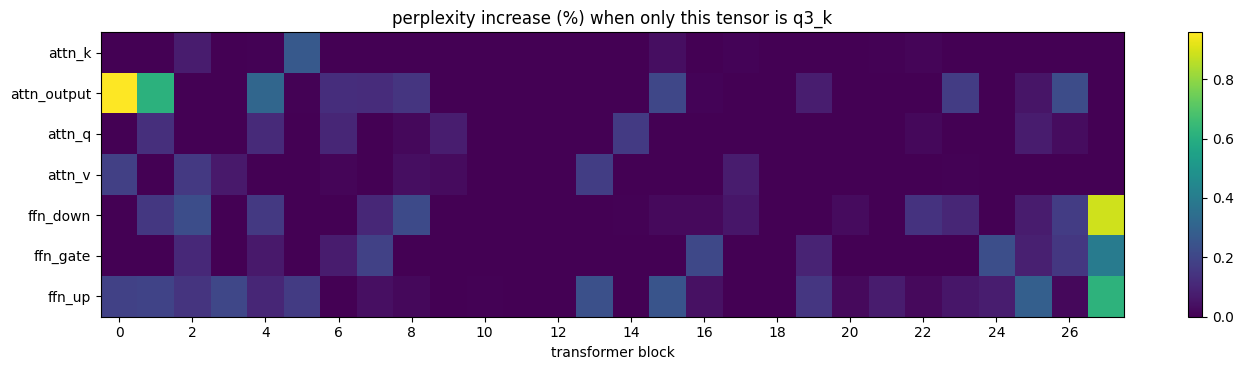

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

ref_dmg = records["dmgref_HIGH"]["ppl"]
def damage_of(name):
    return max(0.0, math.log(records[name]["ppl"] / ref_dmg))      # nats; floored at 0 (noise)

dmg = pd.DataFrame([{**g, "d3": damage_of(f"dmg_{g['id']}_{DMG_LEVEL}")} for g in GROUPS])
dmg["d3_pct"] = 100 * (np.exp(dmg.d3) - 1)
d3_by_id = dict(zip(dmg.id, dmg.d3))

print(f"damage-text reference ppl (q8_0): {ref_dmg:.4f}")
print("\nMost sensitive tensors (keep precise):")
display(dmg.nlargest(8, "d3")[["id", "n", "d3_pct"]].round(3))
print("Most tolerant tensors (compress first):")
display(dmg.nsmallest(8, "d3")[["id", "n", "d3_pct"]].round(3))
print("Mean damage by tensor kind:")
display(dmg.groupby("kind").agg(tensors=("id", "count"), mean_pct=("d3_pct", "mean"), max_pct=("d3_pct", "max")).round(3))

blocks = dmg[dmg.block >= 0]
kinds_order = sorted(blocks.kind.unique())
M = blocks.pivot(index="kind", columns="block", values="d3_pct").loc[kinds_order]
fig, ax = plt.subplots(figsize=(14, 3.8))
im = ax.imshow(M.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(kinds_order))); ax.set_yticklabels(kinds_order)
ax.set_xticks(range(0, M.shape[1], 2)); ax.set_xticklabels(M.columns[::2])
ax.set_xlabel("transformer block"); ax.set_title(f"perplexity increase (%) when only this tensor is {DMG_LEVEL}")
plt.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(RESULTS / f"phase2b_{MODEL_NAME}_damage_heatmap.png", dpi=150)
plt.show()

## 8. Validation sweep: how does damage shrink with more bits?
A subset of the more sensitive tensors is also probed at q4_k, q5_k and q6_k. The median ratio `damage(level) / damage(q3_k)` becomes the global scale the optimizer uses for every group. If there are too few usable points, a simple 6-dB-per-bit law is used instead.

In [12]:
rs = random.Random(0)
top_half = dmg.sort_values("d3", ascending=False).head(max(VAL_GROUPS * 2, len(dmg) // 2))["id"].tolist()
val_ids = rs.sample(top_half, VAL_GROUPS)
for gid in val_ids:
    n = next(g["n"] for g in GROUPS if g["id"] == gid)
    for lvl in VAL_LEVELS:
        evaluate(f"dmg_{gid}_{lvl}", HIGH, [(exact_regex([gid]), lvl)], text=DMG_TEXT, chunks=DMG_CHUNKS,
                 imatrix=True, group="val", gid=gid, level=lvl)

R = {DMG_LEVEL: 1.0}
law = {l: 2 ** (-2 * (BPW[l] - BPW[DMG_LEVEL])) for l in LEVELS}
for lvl in VAL_LEVELS:
    ratios = [damage_of(f"dmg_{gid}_{lvl}") / d3_by_id[gid] for gid in val_ids if d3_by_id[gid] > 1e-3]
    R[lvl] = float(np.median(ratios)) if len(ratios) >= 4 else law[lvl]
prev = 1.0
for lvl in LEVELS[1:-1]:                  # damage must not grow with more bits
    R[lvl] = min(R[lvl], prev); prev = R[lvl]
R[HIGH] = 0.0
print("damage ratio vs", DMG_LEVEL, "(fitted | 6-dB-per-bit law):")
for l in LEVELS:
    print(f"  {l:5s} {R[l]:.4f} | {law[l]:.4f}" if l != HIGH else f"  {l:5s} 0 (reference)")

dmg_blk.6.ffn_gate.weight_q4_k                 size=   1640 MB  ppl=  8.4387  (25s)
dmg_blk.6.ffn_gate.weight_q5_k                 size=   1641 MB  ppl=  8.4500  (25s)
dmg_blk.6.ffn_gate.weight_q6_k                 size=   1643 MB  ppl=  8.4443  (24s)
dmg_blk.14.attn_output.weight_q4_k             size=   1645 MB  ppl=  8.4503  (24s)
dmg_blk.14.attn_output.weight_q5_k             size=   1646 MB  ppl=  8.4428  (24s)
dmg_blk.14.attn_output.weight_q6_k             size=   1646 MB  ppl=  8.4392  (24s)
dmg_blk.21.ffn_up.weight_q4_k                  size=   1640 MB  ppl=  8.4446  (25s)
dmg_blk.21.ffn_up.weight_q5_k                  size=   1641 MB  ppl=  8.4444  (25s)
dmg_blk.21.ffn_up.weight_q6_k                  size=   1643 MB  ppl=  8.4503  (24s)
dmg_blk.27.ffn_gate.weight_q4_k                size=   1640 MB  ppl=  8.4560  (25s)
dmg_blk.27.ffn_gate.weight_q5_k                size=   1641 MB  ppl=  8.4500  (25s)
dmg_blk.27.ffn_gate.weight_q6_k                size=   1643 MB  ppl=  8.4479

## 9. Optimizer: choose a level for every tensor under a size budget
Budgets are the actual sizes of the imatrix presets (Q6_K, Q5_K_M, Q4_K_M, Q3_K_M) plus the midpoints between them, so every candidate can be compared at (almost) equal size.

In [13]:
assert LEVELS[0] == DMG_LEVEL
D = np.array([[d3_by_id[g["id"]] * R[l] for l in LEVELS] for g in GROUPS])
S = size_matrix(N_ELEM, LEVELS)

UP = "uniform_imx_" if USE_IMATRIX else "uniform_"
preset_sizes = sorted((records[UP + q]["size_mb"] for q in UNIFORM if q != "Q2_K"), reverse=True)
budgets = sorted(set(preset_sizes + [(a + b) / 2 for a, b in zip(preset_sizes, preset_sizes[1:])]), reverse=True)
min_mb = (FIXED_BYTES + S[:, 0].sum()) / 1e6
budgets = [b for b in budgets if b * SAFETY > min_mb]
print(f"smallest reachable size (all {DMG_LEVEL}): {min_mb:.0f} MB; budgets (MB):", [round(b) for b in budgets])

def overrides_from_idx(idx):
    by_level = {}
    for g, l in zip(GROUPS, idx):
        if LEVELS[l] != HIGH:
            by_level.setdefault(LEVELS[l], []).append(g["id"])
    return [(exact_regex(names), lvl) for lvl, names in by_level.items()]

plans = {}
for b in budgets:
    cap = b * SAFETY * 1e6 - FIXED_BYTES
    idx, how = solve_allocation(D, S, cap)
    plans[b] = idx
    cnt = {LEVELS[l]: int((idx == l).sum()) for l in range(len(LEVELS))}
    print(f"budget {b:7.0f} MB [{how}] predicted size {(FIXED_BYTES + S[np.arange(len(GROUPS)), idx].sum())/1e6:7.0f} MB, "
          f"predicted damage {D[np.arange(len(GROUPS)), idx].sum():.4f} nats, levels {cnt}")

# which kinds does the optimizer protect?
kind_bits = pd.DataFrame([{"kind": g["kind"], "bpw": BPW[LEVELS[plans[budgets[len(budgets)//2]][i]]]}
                          for i, g in enumerate(GROUPS)]).groupby("kind").bpw.mean().round(2)
print(f"\nmean bits/weight per kind at the middle budget ({budgets[len(budgets)//2]:.0f} MB):")
print(kind_bits.to_string())

smallest reachable size (all q3_k): 670 MB; budgets (MB): [1273, 1199, 1125, 1056, 986, 905, 824]
milp not usable, falling back to greedy: AttributeError("module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'")
budget    1273 MB [greedy] predicted size    1265 MB, predicted damage 0.0000 nats, levels {'q3_k': 44, 'q4_k': 22, 'q5_k': 1, 'q6_k': 0, 'q8_0': 130}
milp not usable, falling back to greedy: AttributeError("module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'")
budget    1199 MB [greedy] predicted size    1193 MB, predicted damage 0.0000 nats, levels {'q3_k': 57, 'q4_k': 29, 'q5_k': 0, 'q6_k': 1, 'q8_0': 110}
milp not usable, falling back to greedy: AttributeError("module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'")
budget    1125 MB [greedy] predicted size    1118 MB, predicted damage 0.0000 nats, levels {'q3_k': 69, 'q4_k': 38, 'q5_k': 0, 'q6_k': 0, 'q8_0': 90}
milp not usable, falling back to greedy: A

## 10. Verify the optimizer's picks with real runs
Each candidate is quantized with the imatrix, evaluated on the **test** text (never used to choose the allocation), and timed with `llama-bench`.

In [14]:
for b in budgets:
    idx = plans[b]
    pred_mb = (FIXED_BYTES + S[np.arange(len(GROUPS)), idx].sum()) / 1e6
    pred_d = float(D[np.arange(len(GROUPS)), idx].sum())
    evaluate(f"opt_{int(round(b))}", HIGH, overrides_from_idx(idx), imatrix=True, do_bench=True,
             group="opt", budget_mb=b, pred_size_mb=pred_mb, pred_dln=pred_d,
             levels=[LEVELS[l] for l in idx])

opt_1273                                       size=   1265 MB  ppl= 10.2758  (83s)
opt_1199                                       size=   1193 MB  ppl= 10.3572  (88s)
opt_1125                                       size=   1118 MB  ppl= 10.4558  (98s)
opt_1056                                       size=   1050 MB  ppl= 10.5397  (106s)
opt_986                                        size=    980 MB  ppl= 10.6056  (119s)
opt_905                                        size=    900 MB  ppl= 10.6637  (127s)
opt_824                                        size=    819 MB  ppl= 10.7302  (138s)


## 11. Results: optimizer vs uniform presets
Success means the green points sit **below** the uniform curves at equal size (better quality) or **right/up** in the speed plot. If they do not, that is a valid finding and the notes at the bottom say what to try next.

,name,budget_mb,pred_size_mb,size_mb,ppl,uniform_ppl_at_size,better_than_uniform_pct,tg_tps
264,opt_824,824.178,818.813,818.813,10.730,10.791,0.562,142.678
263,opt_905,905.113,900.378,900.378,10.664,10.365,-2.799,136.870
262,opt_986,986.048,980.422,980.422,10.606,10.007,-5.647,132.447
261,opt_1056,1055.549,1050.122,1050.122,10.540,9.893,-6.138,126.829
260,opt_1125,1125.050,1118.321,1118.321,10.456,9.799,-6.285,122.007
259,opt_1199,1198.895,1192.697,1192.697,10.357,9.768,-5.690,118.785
258,opt_1273,1272.740,1264.778,1264.778,10.276,9.745,-5.165,115.163


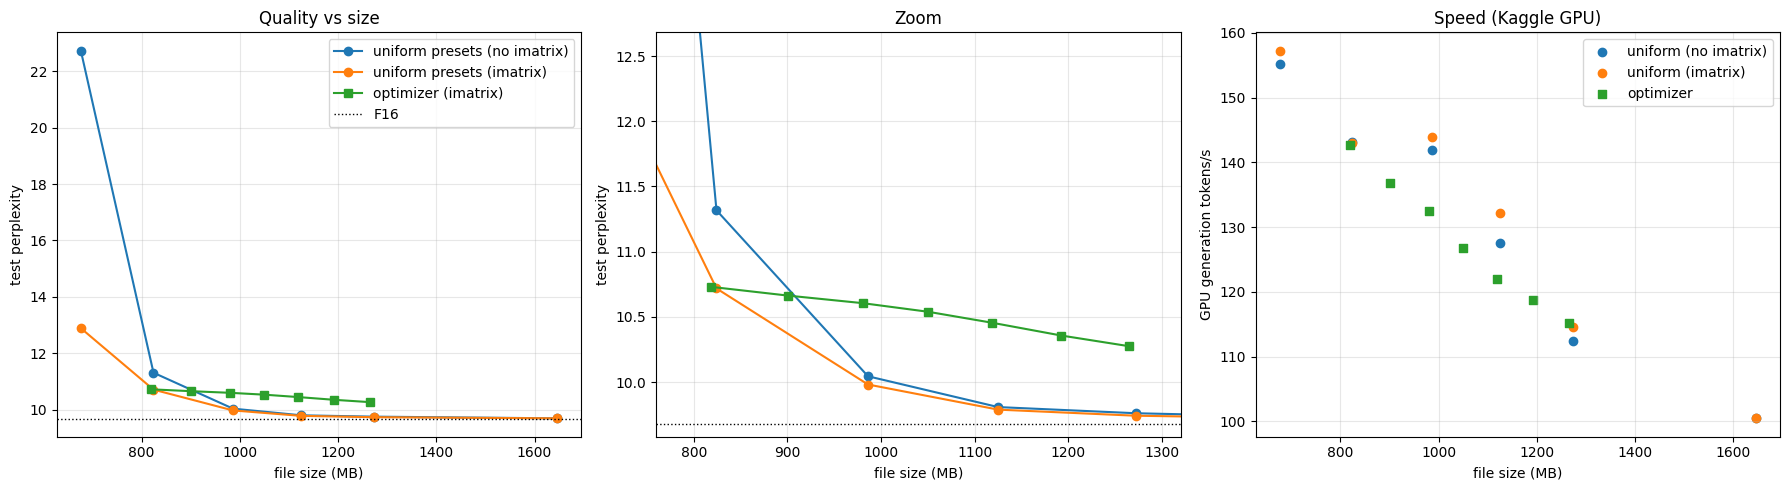

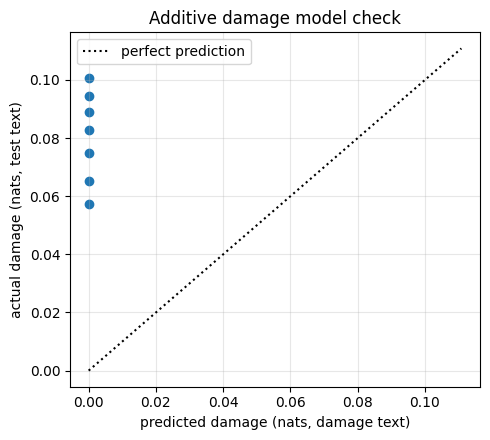

In [15]:
df = pd.DataFrame(records.values())
f16 = records["ref_F16"]["ppl"]
uni = pd.concat([df[df.name == "ref_HIGH_test"], df[df.group == "uniform"]])
uni_plain = uni[(uni.imx != True)].sort_values("size_mb")
uni_imx = uni[(uni.imx == True) | (uni.name == "ref_HIGH_test")].sort_values("size_mb") if USE_IMATRIX else uni_plain
opt = df[df.group == "opt"].sort_values("size_mb")

# comparison at equal size: interpolate the imatrix-preset curve in log(ppl)
xs, ys = uni_imx.size_mb.values, np.log(uni_imx.ppl.values)
opt = opt.assign(uniform_ppl_at_size=np.exp(np.interp(opt.size_mb, xs, ys, left=np.nan, right=np.nan)))
opt["better_than_uniform_pct"] = (opt.uniform_ppl_at_size / opt.ppl - 1) * 100
cols = [c for c in ["name", "budget_mb", "pred_size_mb", "size_mb", "ppl", "uniform_ppl_at_size",
                    "better_than_uniform_pct", "tg_tps"] if c in opt.columns]
display(opt[cols].round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
def curve(a, d, style, label):
    a.plot(d.size_mb, d.ppl, style, label=label)
for a in ax[:2]:
    curve(a, uni_plain, "o-", "uniform presets (no imatrix)")
    if USE_IMATRIX:
        curve(a, uni_imx, "o-", "uniform presets (imatrix)")
    curve(a, opt, "s-", "optimizer (imatrix)")
    a.axhline(f16, color="k", ls=":", lw=1, label="F16")
    a.set_xlabel("file size (MB)"); a.set_ylabel("test perplexity"); a.grid(alpha=.3)
ax[0].set_title("Quality vs size"); ax[0].legend()
ax[1].set_title("Zoom"); ax[1].set_xlim(min(opt.size_mb.min(), 780) - 20, max(opt.size_mb.max(), 1300) + 20)
ax[1].set_ylim(f16 - 0.1, f16 + 3)
if "tg_tps" in df:
    for d, st, lb in [(uni_plain, "o", "uniform (no imatrix)"), (uni_imx, "o", "uniform (imatrix)"), (opt, "s", "optimizer")]:
        if "tg_tps" in d and d.tg_tps.notna().any():
            ax[2].scatter(d.size_mb, d.tg_tps, marker=st, label=lb)
    ax[2].set_xlabel("file size (MB)"); ax[2].set_ylabel("GPU generation tokens/s"); ax[2].set_title("Speed (Kaggle GPU)")
    ax[2].grid(alpha=.3); ax[2].legend()
plt.tight_layout()
plt.savefig(RESULTS / f"phase2b_{MODEL_NAME}_optimizer_vs_uniform.png", dpi=150)
plt.show()

# is the additive damage model any good? predicted vs actual (actual on TEST text, so only roughly comparable)
ref_test = records["ref_HIGH_test"]["ppl"]
opt = opt.assign(actual_dln=np.log(opt.ppl / ref_test))
fig, a = plt.subplots(figsize=(5, 4.5))
a.scatter(opt.pred_dln, opt.actual_dln)
lim = max(opt.pred_dln.max(), opt.actual_dln.max()) * 1.1
a.plot([0, lim], [0, lim], "k:", label="perfect prediction")
a.set_xlabel("predicted damage (nats, damage text)"); a.set_ylabel("actual damage (nats, test text)")
a.set_title("Additive damage model check"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / f"phase2b_{MODEL_NAME}_model_check.png", dpi=150); plt.show()

## 12. Save everything, then clean up
The allocations and the damage table are the **inputs for Phase 3** (the search). The big model files are deleted at the end so Save Version stays fast.

In [16]:
df.to_csv(RESULTS / f"phase2b_{MODEL_NAME}_all_results.csv", index=False)
dmg_out = dmg.copy()
for l in LEVELS:
    dmg_out[f"pred_{l}"] = dmg_out.d3 * R[l]
dmg_out.to_csv(RESULTS / f"phase2b_{MODEL_NAME}_damage_table.csv", index=False)
allocs = {str(int(round(b))): {g["id"]: LEVELS[l] for g, l in zip(GROUPS, plans[b])} for b in budgets}
(RESULTS / f"phase2b_{MODEL_NAME}_allocations.json").write_text(json.dumps(allocs, indent=1))
meta = {"model": MODEL_ID, "llama_cpp_commit": LLAMA_COMMIT, "levels": LEVELS, "damage_ratios": R,
        "fixed_bytes": FIXED_BYTES, "n_groups": len(GROUPS), "dmg_chunks": DMG_CHUNKS, "ppl_chunks": PPL_CHUNKS,
        "imx_chunks": IMX_CHUNKS, "use_imatrix": USE_IMATRIX,
        "gpu": sh("nvidia-smi -i 0 --query-gpu=name --format=csv,noheader", check=False),
        "date": time.strftime("%Y-%m-%d %H:%M")}
(RESULTS / f"phase2b_{MODEL_NAME}_meta.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

if CLEANUP:
    shutil.rmtree(WORK / "hf", ignore_errors=True)
    shutil.rmtree(MODELS, ignore_errors=True)
    print(sh(f"du -sh {WORK}", check=False))

$ nvidia-smi -i 0 --query-gpu=name --format=csv,noheader
{
  "model": "Qwen/Qwen2.5-1.5B",
  "llama_cpp_commit": "f5027fb",
  "levels": [
    "q3_k",
    "q4_k",
    "q5_k",
    "q6_k",
    "q8_0"
  ],
  "damage_ratios": {
    "q3_k": 1.0,
    "q4_k": 0.0,
    "q5_k": 0.0,
    "q6_k": 0.0,
    "q8_0": 0.0
  },
  "fixed_bytes": 6530016.0,
  "n_groups": 197,
  "dmg_chunks": 30,
  "ppl_chunks": 100,
  "imx_chunks": 200,
  "use_imatrix": true,
  "gpu": "Tesla T4",
  "date": "2026-10-23 11:42"
}
$ du -sh /kaggle/working
440M	/kaggle/working


## How to read the result
1. **Optimizer below the imatrix-preset curve (section 11)?** That is the headline result. Report the equal-size comparison table.
2. **Predicted vs actual damage close to the diagonal?** Then the additive model is trustworthy and the Phase 3 search can lean on it. Large deviations mean interactions matter, and Phase 3 should evaluate more real candidates.
3. **Which kinds does the optimizer protect?** The per-kind bits table shows what a good allocation looks like (often `ffn_down`, `attn_v` and the embeddings stay higher). This is a result worth explaining in the write-up.
4. **If it does not beat the presets:** the K-quant presets are already well tuned, so a tie is plausible. Then the case for the project rests on (a) **speed**: choose configs by measured tokens/s on the target device, (b) **device budgets** the presets do not know about, and (c) an honest analysis of why a tuned preset is hard to beat.

**Next (Phase 3):** use `damage_table.csv` and the fitted ratios as the model inside a search that also measures real latency and memory on the laptop/CPU, then re-verify the best candidates with real runs.

In [2]:
import os, pathlib
p = pathlib.Path("/kaggle/working/results/phase2b_Qwen2.5-1.5B.jsonl")
print("results file exists:", p.exists(), "| lines:", sum(1 for _ in open(p)) if p.exists() else 0)
print("llama.cpp built:", os.path.exists("/kaggle/working/llama.cpp/build/bin/llama-quantize"))

results file exists: False | lines: 0
llama.cpp built: False
